# Real Estate Price Analysis

## Introduction

Residential property prices depend on various structural and qualitative characteristics such as living area, number of rooms, quality, age, and garage capacity. Understanding these relationships is useful for estimating property prices and identifying the factors that drive differences in housing values.

In this project, the **Ames Housing dataset** is used to develop an interpretable **Multiple Linear Regression** model for predicting residential property prices. The analysis focuses not only on prediction but also on understanding the relationship between property characteristics and sale price.

The project includes exploratory data analysis, feature selection, handling of missing values and categorical variables, and regression diagnostics to assess assumptions such as **multicollinearity, heteroscedasticity, residual behaviour, and influential observations**.

## Problem Statement

The objective is to build a statistically interpretable model that estimates house sale prices from relevant property characteristics while assessing the reliability of the regression assumptions.

### Key Objectives

- Explore the housing data and identify important relationships.
- Handle missing values and categorical variables appropriately.
- Select relevant predictors for the regression model.
- Build a **Multiple Linear Regression** model for house prices.
- Evaluate model performance using \(R^2\), RMSE, and MAE.
- Perform regression diagnostics and interpret the key factors associated with sale prices.

In [2]:
# Importing Libraries 

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

## Loading the Dataset

The dataset contains information about residential properties and their characteristics. Each observation represents a house, while the variables describe different structural, quality, location, and other property-related features.

The target variable for this analysis is `SalePrice`.

In [5]:
df = pd.read_csv("train.csv")

In [7]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Initial Data Exploration

Before cleaning or modelling the data, it is important to understand the size, structure, variable types, and overall characteristics of the dataset.

In [10]:
df.shape

(1460, 81)

The dataset contains 1460 observations and 81 variables. Each observation represents a residential property, while the variables contain information about different characteristics of the property.

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

The dataset contains both numerical and categorical variables. Several variables also contain missing values, which will need to be addressed before regression modelling.

In [18]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [20]:
missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

missing_values

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

In [26]:
missing_percentage = (
    df.isnull().sum() /
    len(df)
) * 100

missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

missing_percentage

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

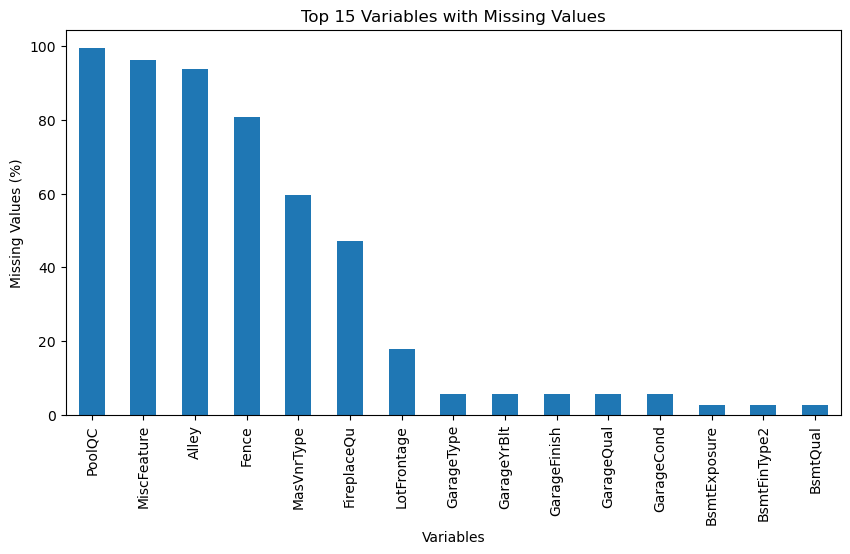

In [28]:
missing_percentage.head(15).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 15 Variables with Missing Values")

plt.xlabel("Variables")

plt.ylabel("Missing Values (%)")

plt.xticks(rotation=90)

plt.show()

### Missing Values Analysis

The bar chart shows the **top 15 variables with the highest percentage of missing values** in the dataset.

- **PoolQC, MiscFeature, and Alley** have extremely high percentages of missing values, close to or above **90%**.
- **Fence, MasVnrType, and FireplaceQu** also contain a substantial number of missing values.
- Variables such as **GarageType, GarageYrBlt, GarageFinish, GarageQual, GarageCond, BsmtExposure, BsmtFinType2, and BsmtQual** have relatively fewer missing values.

The variables with a very high percentage of missing values may need to be **dropped or carefully handled**, as imputing a large number of missing values may not be reliable. For variables with fewer missing values, appropriate imputation techniques can be used during the data preprocessing stage.

In [31]:
df.duplicated().sum()

np.int64(0)

No duplicate observations were found in the dataset.

## Data Cleaning

In [35]:
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = df.select_dtypes(
    include=["object"]
).columns

In [37]:
print(
    "Number of Numerical Features:",
    len(numerical_features)
)

print(
    "Number of Categorical Features:",
    len(categorical_features)
)

Number of Numerical Features: 38
Number of Categorical Features: 43


In [54]:
none_columns = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

df[none_columns] = df[none_columns].fillna("None")

In [56]:
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

In [58]:
df["MasVnrType"] = df["MasVnrType"].fillna("None")

In [60]:
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

In [62]:
df["LotFrontage"] = df.groupby(
    "Neighborhood"
)["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

### Handling Missing LotFrontage Values

The `LotFrontage` variable represents the linear feet of street connected to the property.

Since properties within the same neighborhood may have similar characteristics, missing values were first replaced using the median `LotFrontage` within each neighborhood.

Any remaining missing values were replaced using the overall median.

In [65]:
df["Electrical"] = df["Electrical"].fillna(
    df["Electrical"].mode()[0]
)

In [67]:
print(
    "Total Missing Values:",
    df.isnull().sum().sum()
)

Total Missing Values: 0


In [71]:
remaining_missing = df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

remaining_missing

Series([], dtype: int64)

## Exploratory Data Analysis

In [74]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

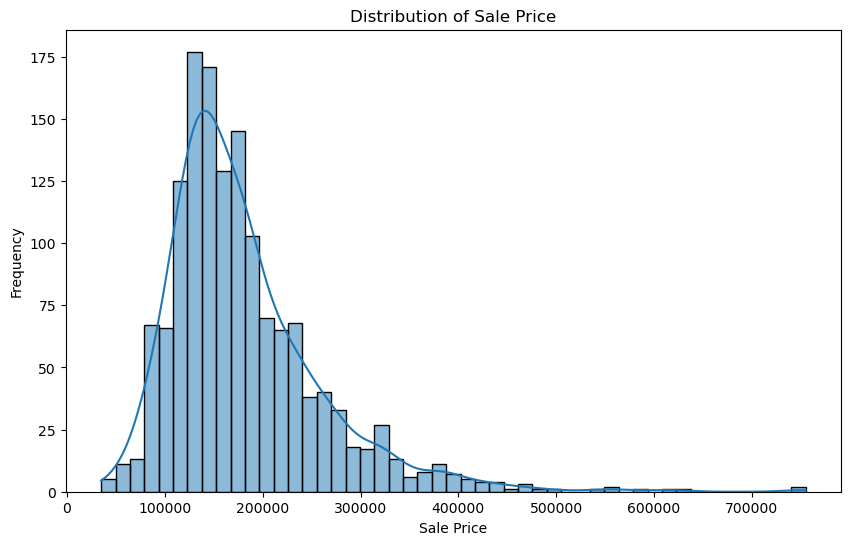

In [76]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["SalePrice"],
    kde=True
)

plt.title("Distribution of Sale Price")

plt.xlabel("Sale Price")

plt.ylabel("Frequency")

plt.show()

### Distribution of Sale Price

The histogram shows the distribution of the `SalePrice` variable. Most houses have sale prices between approximately **100,000 and 200,000**, with the highest concentration around **130,000–160,000**.

The distribution is **positively skewed (right-skewed)**, as there is a long tail towards higher sale prices. A small number of houses have exceptionally high prices, which may be considered potential outliers.

Since `SalePrice` is not normally distributed, a **log transformation** may be considered later to reduce skewness and improve the performance of the regression model.

In [79]:
print(
    "Skewness of SalePrice:",
    df["SalePrice"].skew()
)

Skewness of SalePrice: 1.8828757597682129


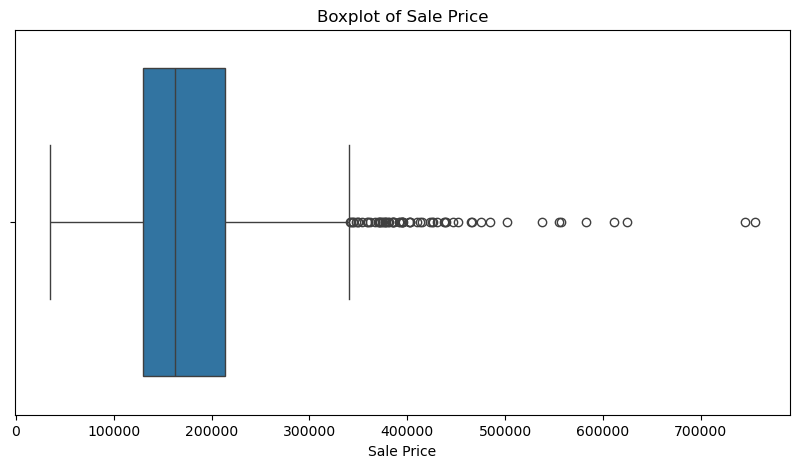

In [81]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["SalePrice"]
)

plt.title("Boxplot of Sale Price")

plt.xlabel("Sale Price")

plt.show()

## Feature Relationship Analysis

After analyzing the distribution of the target variable, we now examine the relationship between important numerical features and `SalePrice`.

Correlation analysis and visualizations are used to identify the variables that have the strongest relationship with house prices.

In [84]:
numerical_df = df.select_dtypes(include=["int64", "float64"])

correlation_with_price = numerical_df.corr()["SalePrice"].sort_values(
    ascending=False
)

correlation_with_price

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.472614
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.349876
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
GarageYrBlt      0.261366
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [86]:
top_features = correlation_with_price.head(10)

top_features

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64

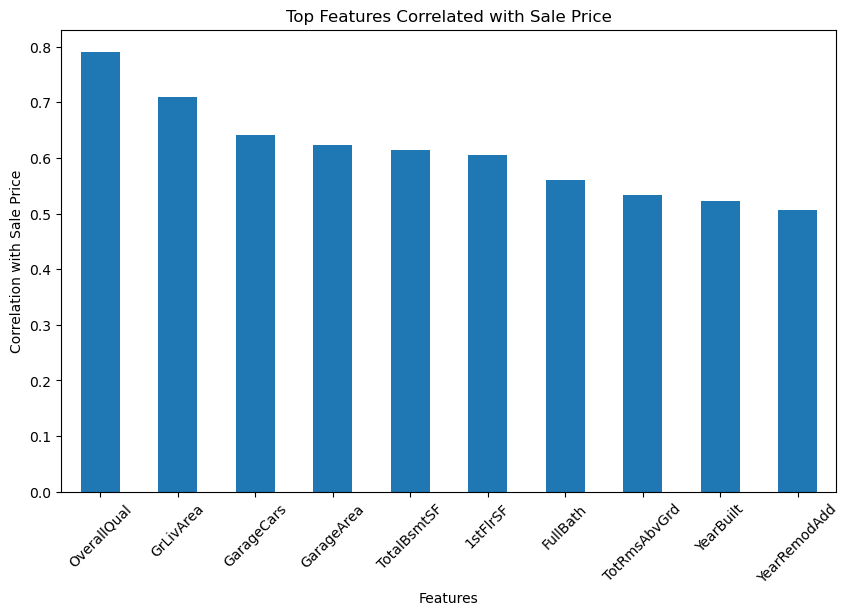

In [88]:
top_features_without_target = correlation_with_price.drop(
    "SalePrice"
).head(10)

plt.figure(figsize=(10, 6))

top_features_without_target.plot(
    kind="bar"
)

plt.title("Top Features Correlated with Sale Price")
plt.xlabel("Features")
plt.ylabel("Correlation with Sale Price")

plt.xticks(rotation=45)

plt.show()

### Top Features Correlated with Sale Price

The bar chart shows the numerical features with the strongest positive correlation with `SalePrice`.

`OverallQual` has the highest correlation with sale price, followed by `GrLivArea`. This suggests that the overall quality of a house and its above-ground living area are important factors in determining its price.

Other important features include `GarageCars`, `GarageArea`, `TotalBsmtSF`, and `1stFlrSF`. These features will be examined further using correlation heatmaps and individual visualizations.

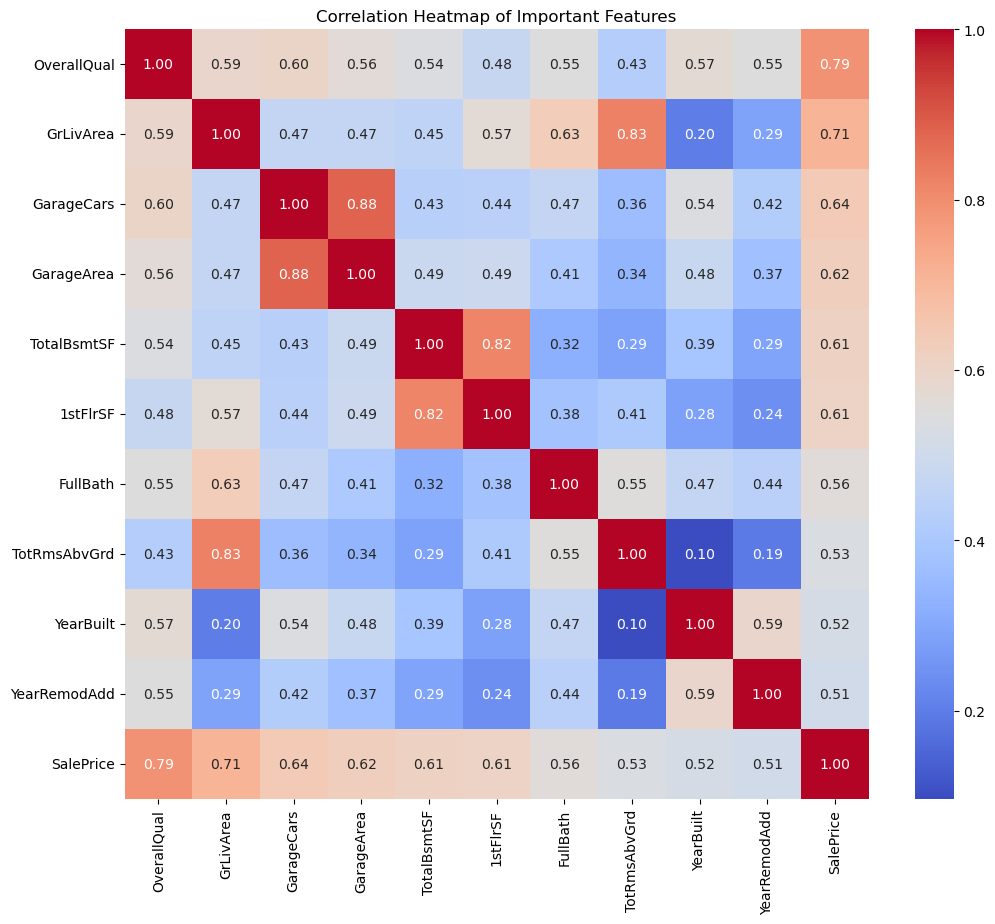

In [91]:
important_features = top_features_without_target.index.tolist()

important_features.append("SalePrice")

plt.figure(figsize=(12, 10))

sns.heatmap(
    df[important_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Important Features")

plt.show()

### Correlation Heatmap of Important Features

The heatmap shows the relationships between the top numerical features and `SalePrice`.

`OverallQual` has the strongest correlation with `SalePrice` (0.79), followed by `GrLivArea` (0.71). This indicates that the overall quality of the house and the above-ground living area are important factors in determining house prices.

Other features such as `GarageCars`, `GarageArea`, `TotalBsmtSF`, and `1stFlrSF` also show moderately strong positive correlations with `SalePrice`.

The heatmap also reveals strong relationships between some predictor variables. For example:

- `GarageCars` and `GarageArea` have a high correlation of 0.88.
- `TotalBsmtSF` and `1stFlrSF` have a high correlation of 0.82.
- `GrLivArea` and `TotRmsAbvGrd` have a high correlation of 0.83.

These highly correlated predictor variables may provide similar information and should be considered while building the multiple linear regression model to avoid potential multicollinearity.

## Multicollinearity Analysis Using VIF

In [107]:
import pandas as pd

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

We should not include **SalePrice** as that is our target variable

In [99]:
X_vif = df[important_features].drop(columns="SalePrice")

In [101]:
X_vif.columns

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd'],
      dtype='object')

In [109]:
X_vif_const = add_constant(X_vif)

In [111]:
X_vif_const.head()

,const,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
0,1.0,7,1710,2,548,856,856,2,8,2003,2003
1,1.0,6,1262,2,460,1262,1262,2,6,1976,1976
2,1.0,7,1786,2,608,920,920,2,6,2001,2002
3,1.0,7,1717,3,642,756,961,1,7,1915,1970
4,1.0,8,2198,3,836,1145,1145,2,9,2000,2000


In [113]:
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif_const.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif_const.values,
        i
    )
    for i in range(X_vif_const.shape[1])
]

vif_data

,Feature,VIF
0,const,16924.754184
1,OverallQual,2.748629
2,GrLivArea,5.018752
3,GarageCars,5.250959
4,GarageArea,4.931012
5,TotalBsmtSF,3.602674
6,1stFlrSF,3.684726
7,FullBath,2.215500
8,TotRmsAbvGrd,3.356517
9,YearBuilt,2.345827


In [115]:
vif_data = vif_data[
    vif_data["Feature"] != "const"
]

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

vif_data

,Feature,VIF
3,GarageCars,5.250959
2,GrLivArea,5.018752
4,GarageArea,4.931012
6,1stFlrSF,3.684726
5,TotalBsmtSF,3.602674
8,TotRmsAbvGrd,3.356517
1,OverallQual,2.748629
9,YearBuilt,2.345827
7,FullBath,2.215500
10,YearRemodAdd,1.751047


### VIF Results

The VIF analysis indicates that there is no severe multicollinearity among the selected predictor variables.

Most features have VIF values below 5. `GarageCars` and `GrLivArea` have VIF values slightly above 5, indicating moderate multicollinearity. However, the values are not high enough to indicate a serious multicollinearity problem.

Therefore, all the selected features will be retained for further analysis and model building.

## Target Variable Transformation

In [123]:
df["SalePrice"].skew()

np.float64(1.8828757597682129)



The distribution of the target variable, `SalePrice`, is positively skewed. The skewness value is approximately 1.83, indicating a strong right-skewed distribution.

To reduce the skewness and make the distribution closer to normal, a logarithmic transformation will be applied to `SalePrice`.

The transformed target variable will be used for building the Multiple Linear Regression model.

In [126]:
import numpy as np

df["LogSalePrice"] = np.log1p(df["SalePrice"])

df[["SalePrice", "LogSalePrice"]].head()

,SalePrice,LogSalePrice
0,208500,12.247699
1,181500,12.109016
2,223500,12.317171
3,140000,11.849405
4,250000,12.429220


In [128]:
print(
    "Original SalePrice Skewness:",
    df["SalePrice"].skew()
)

print(
    "Log-Transformed SalePrice Skewness:",
    df["LogSalePrice"].skew()
)

Original SalePrice Skewness: 1.8828757597682129
Log-Transformed SalePrice Skewness: 0.12134661989685333


### Interpretation

The original `SalePrice` variable had a skewness of approximately 1.88, indicating a strongly right-skewed distribution.

After applying the logarithmic transformation using `np.log1p()`, the skewness decreased to approximately 0.12. This indicates that the transformed target variable is much closer to a symmetric distribution.

Therefore, `LogSalePrice` will be used as the target variable for building the Multiple Linear Regression model.

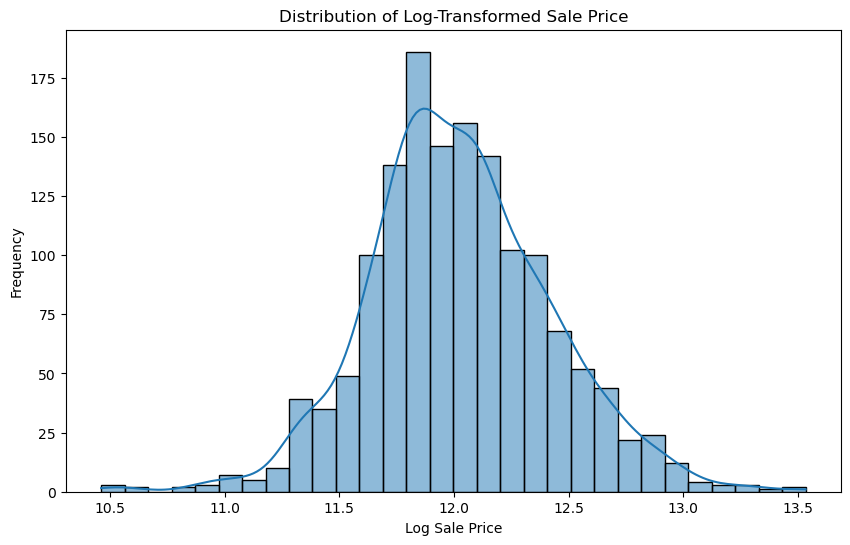

In [131]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["LogSalePrice"],
    bins=30,
    kde=True
)

plt.title("Distribution of Log-Transformed Sale Price")
plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")

plt.show()

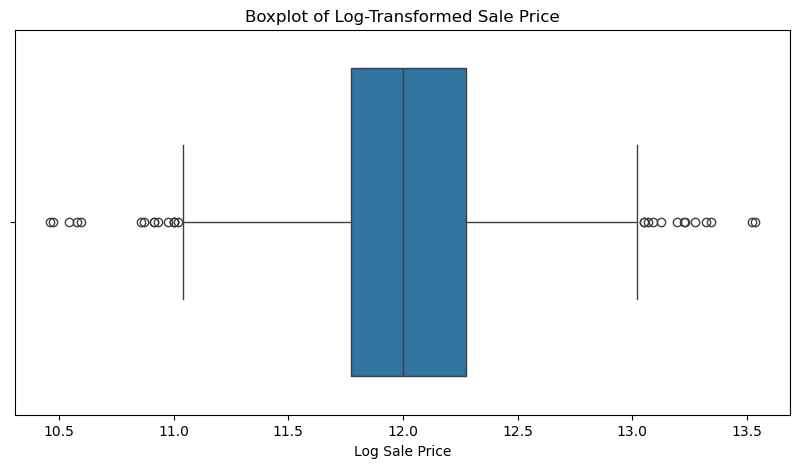

In [133]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["LogSalePrice"]
)

plt.title("Boxplot of Log-Transformed Sale Price")
plt.xlabel("Log Sale Price")

plt.show()

### Interpretation of Target Variable Transformation

The original `SalePrice` variable was strongly right-skewed. After applying the logarithmic transformation, the distribution became much more symmetric and closer to a normal distribution.

The skewness decreased from approximately 1.88 to 0.12, indicating a significant improvement in the distribution.

Although a few observations remain at the extreme ends, their influence has been reduced. Therefore, `LogSalePrice` will be used as the target variable for building the Multiple Linear Regression model.

# Feature Selection and Data Preparation

The predictor variables were selected based on their correlation with `SalePrice` and their multicollinearity levels.

The selected features have a strong relationship with the target variable and do not show severe multicollinearity after the VIF analysis.

These features will be used as independent variables for building the Multiple Linear Regression model.

In [137]:
selected_features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd"
]

selected_features

['OverallQual',
 'GrLivArea',
 'GarageCars',
 'GarageArea',
 'TotalBsmtSF',
 '1stFlrSF',
 'FullBath',
 'TotRmsAbvGrd',
 'YearBuilt',
 'YearRemodAdd']

In [139]:
df[selected_features + ["LogSalePrice"]].isnull().sum()

OverallQual     0
GrLivArea       0
GarageCars      0
GarageArea      0
TotalBsmtSF     0
1stFlrSF        0
FullBath        0
TotRmsAbvGrd    0
YearBuilt       0
YearRemodAdd    0
LogSalePrice    0
dtype: int64

## Defining Independent and Target Variables

The selected predictor variables will be stored in `X`, while the log-transformed house price will be stored in `y`.

- `X` represents the independent variables.
- `y` represents the target variable.

In [142]:
X = df[selected_features]

y = df["LogSalePrice"]

In [144]:
print("Shape of X:", X.shape)

print("Shape of y:", y.shape)

Shape of X: (1460, 10)
Shape of y: (1460,)


In [146]:
X.head()

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
0,7,1710,2,548,856,856,2,8,2003,2003
1,6,1262,2,460,1262,1262,2,6,1976,1976
2,7,1786,2,608,920,920,2,6,2001,2002
3,7,1717,3,642,756,961,1,7,1915,1970
4,8,2198,3,836,1145,1145,2,9,2000,2000


y.head()

## Train-Test Split

Before building the multiple linear regression model, we split the dataset into training and testing sets. The model will be trained using the training data and evaluated using the testing data.

We use 80% of the data for training and 20% for testing.

In [154]:
from sklearn.model_selection import train_test_split

In [156]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [158]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1168, 10)
X_test shape: (292, 10)
y_train shape: (1168,)
y_test shape: (292,)


## Feature Scaling

The selected features have different scales and units. For example, OverallQual is measured on a rating scale, while GrLivArea is measured in square feet.

Therefore, we standardize the predictor variables so that they have a mean of 0 and a standard deviation of 1. This ensures that all features are placed on a comparable scale.

In [162]:
from sklearn.preprocessing import StandardScaler

In [164]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [166]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (1168, 10)
X_test_scaled shape: (292, 10)


## Multiple Linear Regression Model

Multiple Linear Regression is used to model the relationship between one continuous target variable and multiple predictor variables.

In this project, the model uses the selected house features to predict the log-transformed SalePrice.

In [169]:
from sklearn.linear_model import LinearRegression

In [171]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[0.13,0.11,0.06,...,0.01,0.06,0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,12.03
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,10
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[77.32,41.05,36.18,...,13.25,12.75,10.97]"


In [173]:
y_train_pred = linear_model.predict(X_train_scaled)

y_test_pred = linear_model.predict(X_test_scaled)

In [175]:
comparison = pd.DataFrame({
    "Actual Log SalePrice": y_test.values,
    "Predicted Log SalePrice": y_test_pred
})

comparison.head(10)

,Actual Log SalePrice,Predicted Log SalePrice
0,11.947956,11.877499
1,12.691584,12.588840
2,11.652696,11.661127
3,11.976666,11.917281
4,12.661917,12.611441
5,11.231901,11.373957
6,12.649158,12.211655
7,11.891369,11.976920
8,11.344519,11.365665
9,11.816734,11.718346


## Model Evaluation

The performance of the Multiple Linear Regression model is evaluated using different regression metrics.

We evaluate the model using R² Score, Adjusted R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

In [179]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [181]:
import numpy as np

# R² Score
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

# MAE
mae = mean_absolute_error(y_test, y_test_pred)

# MSE
mse = mean_squared_error(y_test, y_test_pred)

# RMSE
rmse = np.sqrt(mse)

print("Training R² Score:", r2_train)
print("Testing R² Score:", r2_test)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

Training R² Score: 0.8121145578321868
Testing R² Score: 0.8440431435643247
MAE: 0.11902123563627016
MSE: 0.029103263156698967
RMSE: 0.17059678530587546


## Adjusted R² Score

Adjusted R² is a modified version of R² that takes into account the number of predictor variables used in the model. Unlike R², Adjusted R² penalizes the inclusion of unnecessary features.

In [185]:
# Number of observations in the test set
n = X_test.shape[0]

# Number of predictor variables
p = X_test.shape[1]

# Calculate Adjusted R²
adjusted_r2 = 1 - (1 - r2_test) * (n - 1) / (n - p - 1)

print("Testing Adjusted R² Score:", adjusted_r2)

Testing Adjusted R² Score: 0.8384930774989983


### Interpretation of Adjusted R²

The testing R² score of approximately 0.844 indicates that the model explains about 84.4% of the variation in the log-transformed SalePrice.

The adjusted R² score is approximately 0.8385. Since adjusted R² accounts for the number of predictor variables in the model, it provides a more reliable measure when multiple features are used.

The small difference between R² and adjusted R² suggests that the selected predictor variables are contributing reasonably well to the model and that there is no strong indication of unnecessary features.

### Converting Predictions Back to Original Price Scale

Since the target variable was transformed using the natural logarithm, the predictions need to be converted back to the original SalePrice scale for easier interpretation.

In [191]:
# Convert log-transformed predictions back to original SalePrice scale

y_test_actual = np.exp(y_test)

y_test_pred_original = np.exp(y_test_pred)

In [193]:
price_comparison = pd.DataFrame({
    "Actual SalePrice": y_test_actual,
    "Predicted SalePrice": y_test_pred_original
})

price_comparison.head(10)

,Actual SalePrice,Predicted SalePrice
892,154501.0,143989.923664
1105,325001.0,293267.337216
413,115001.0,115974.671643
522,159001.0,149833.698558
1036,315501.0,299971.040520
614,75501.0,87025.518310
218,311501.0,201119.652042
1160,146001.0,159041.433358
649,84501.0,86306.886957
887,135501.0,122804.110713


### Model Evaluation on Original SalePrice Scale

Since the target variable was log-transformed before training the model, the predictions are converted back to the original SalePrice scale. The evaluation metrics below provide an interpretation of the model's prediction error in terms of actual house prices.

In [196]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics on original SalePrice scale

mae_original = mean_absolute_error(
    y_test_actual,
    y_test_pred_original
)

mse_original = mean_squared_error(
    y_test_actual,
    y_test_pred_original
)

rmse_original = np.sqrt(mse_original)

r2_original = r2_score(
    y_test_actual,
    y_test_pred_original
)

print("MAE:", mae_original)
print("MSE:", mse_original)
print("RMSE:", rmse_original)
print("R² Score:", r2_original)

MAE: 20584.29476567722
MSE: 1007196424.554404
RMSE: 31736.358085867447
R² Score: 0.8686892320680368


### Interpretation of Model Performance on Original SalePrice Scale

The model achieved an R² score of approximately 0.869 on the original SalePrice scale. This indicates that the model explains about 86.9% of the variation in house prices.

The Mean Absolute Error (MAE) is approximately 20,584, meaning that the predicted house price differs from the actual house price by around 20,584 units on average.

The Root Mean Squared Error (RMSE) is approximately 31,736. Since RMSE is higher than MAE, some predictions have relatively larger errors.

Overall, the Multiple Linear Regression model demonstrates reasonably good predictive performance on the test data.

## Actual vs Predicted House Prices

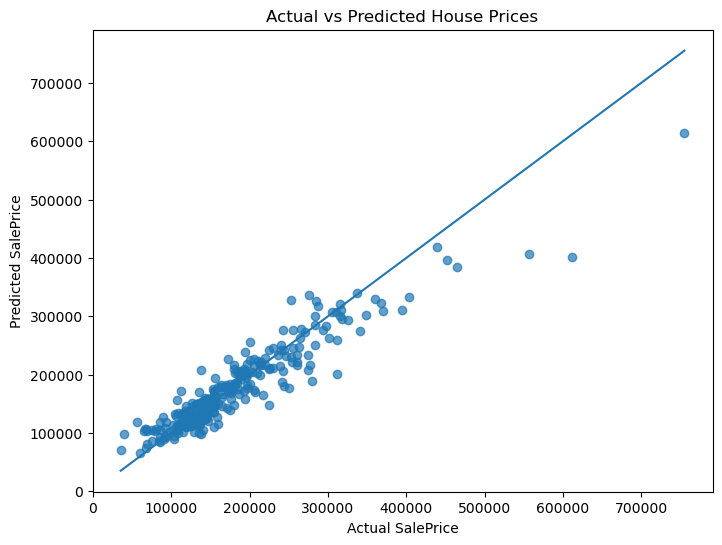

In [200]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_actual,
    y_test_pred_original,
    alpha=0.7
)

# Perfect prediction reference line
plt.plot(
    [y_test_actual.min(), y_test_actual.max()],
    [y_test_actual.min(), y_test_actual.max()]
)

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted House Prices")

plt.show()

### Interpretation

The Actual vs Predicted plot compares the true house prices with the prices predicted by the Multiple Linear Regression model.

The diagonal line represents perfect predictions, where the predicted SalePrice is equal to the actual SalePrice. Most observations are located reasonably close to this line, indicating that the model performs well for many houses.

However, some observations, particularly houses with higher prices, are farther from the diagonal line. This indicates larger prediction errors for these houses. Overall, the plot supports the evaluation metrics and suggests that the model provides reasonably good predictions.

## Residual Analysis

Residual analysis is used to examine the difference between the actual and predicted values. It helps evaluate whether the assumptions of the linear regression model are reasonably satisfied.

In [204]:
# Calculate residuals on the original SalePrice scale

residuals = y_test_actual - y_test_pred_original

# Display the first few residuals
residuals.head()

892     10511.076336
1105    31733.662784
413      -973.671643
522      9167.301442
1036    15529.959480
Name: LogSalePrice, dtype: float64

## Residual Plot

A residual plot shows the relationship between the predicted values and the residuals. 

For a good linear regression model, residuals should be randomly scattered around zero without showing a clear pattern.

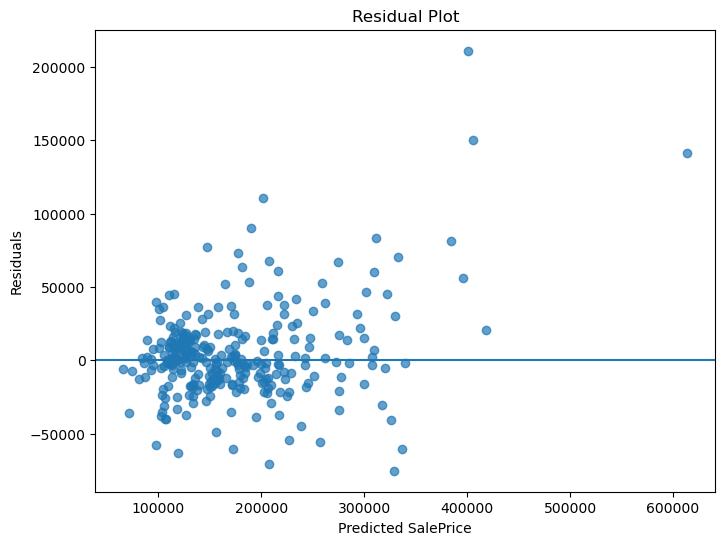

In [209]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test_pred_original, residuals, alpha=0.7)

plt.axhline(y=0)

plt.xlabel("Predicted SalePrice")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

### Residual Distribution

The distribution of residuals helps examine whether the errors are approximately normally distributed. For a linear regression model, residuals should ideally be centered around zero and approximately follow a normal distribution.

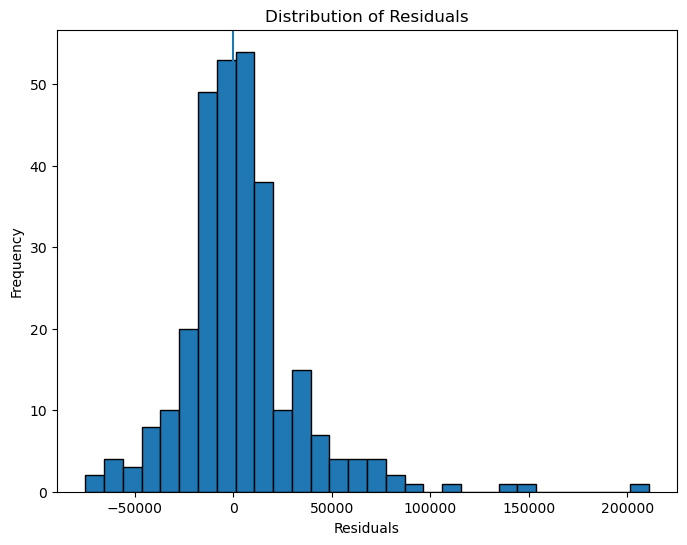

In [212]:
plt.figure(figsize=(8, 6))

plt.hist(residuals, bins=30, edgecolor="black")

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.axvline(x=0)

plt.show()

### Interpretation

Most residuals are concentrated around zero, indicating that the model makes reasonably accurate predictions for many houses. However, the distribution is slightly right-skewed due to a few large positive residuals.

These large positive residuals indicate that the model significantly underpredicts the prices of some houses. Therefore, although the residuals are generally centered around zero, the presence of outliers suggests that the model has more difficulty predicting certain high-priced houses accurately.

## Feature Coefficients

In Multiple Linear Regression, each predictor variable has a coefficient that represents its relationship with the target variable while keeping the other variables constant.

A positive coefficient indicates a positive relationship with the predicted SalePrice, while a negative coefficient indicates a negative relationship.

In [218]:
coefficients = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": linear_model.coef_
})

coefficients

,Feature,Coefficient
0,OverallQual,0.128728
1,GrLivArea,0.111571
2,GarageCars,0.060262
3,GarageArea,0.010299
4,TotalBsmtSF,0.028639
5,1stFlrSF,0.023977
6,FullBath,-0.014816
7,TotRmsAbvGrd,0.011369
8,YearBuilt,0.059030
9,YearRemodAdd,0.046027


In [220]:
coefficients_sorted = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

coefficients_sorted

,Feature,Coefficient
0,OverallQual,0.128728
1,GrLivArea,0.111571
2,GarageCars,0.060262
8,YearBuilt,0.059030
9,YearRemodAdd,0.046027
4,TotalBsmtSF,0.028639
5,1stFlrSF,0.023977
6,FullBath,-0.014816
7,TotRmsAbvGrd,0.011369
3,GarageArea,0.010299


### Feature Importance

The absolute values of the standardized regression coefficients are used to compare the relative influence of the selected predictor variables on the predicted house price.

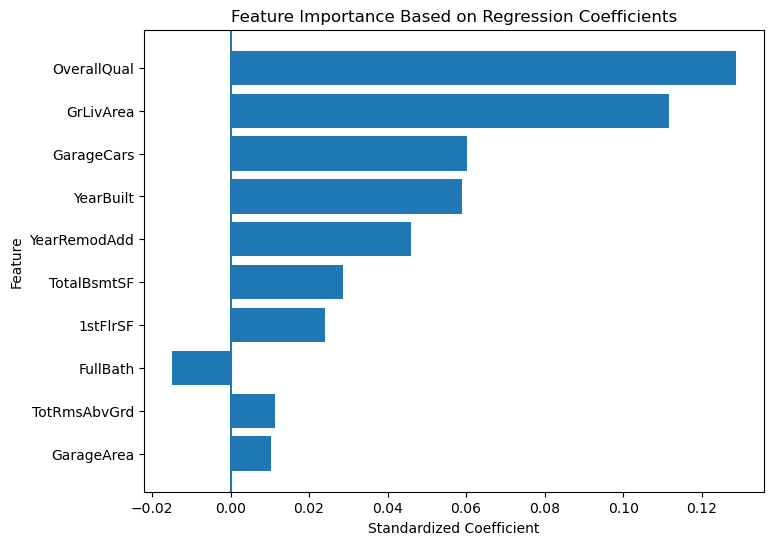

In [223]:
coefficients_sorted_plot = coefficients.copy()

coefficients_sorted_plot["Absolute Coefficient"] = (
    coefficients_sorted_plot["Coefficient"].abs()
)

coefficients_sorted_plot = coefficients_sorted_plot.sort_values(
    by="Absolute Coefficient",
    ascending=True
)

plt.figure(figsize=(8, 6))

plt.barh(
    coefficients_sorted_plot["Feature"],
    coefficients_sorted_plot["Coefficient"]
)

plt.xlabel("Standardized Coefficient")
plt.ylabel("Feature")
plt.title("Feature Importance Based on Regression Coefficients")

plt.axvline(x=0)

plt.show()

## Interpretation of Feature Importance

The standardized regression coefficients help us understand the relative influence of each feature on the predicted house price.

- `OverallQual` has the strongest positive influence on house prices among the selected features.
- `GrLivArea` is also an important predictor, indicating that houses with larger living areas generally tend to have higher prices.
- `YearBuilt` and `YearRemodAdd` have positive relationships with house prices, suggesting that newer or recently renovated houses tend to have higher values.
- `FullBath` has a negative coefficient in this model. This does not necessarily mean that having more bathrooms reduces house prices. The negative coefficient may result from relationships between predictor variables and should be interpreted while considering the other features in the model.

Overall, the analysis shows that house quality, living area, age, and garage-related features play important roles in predicting house prices.

## Multicollinearity Analysis

Multiple Linear Regression can be affected by multicollinearity, which occurs when two or more predictor variables are highly correlated with each other.

The Variance Inflation Factor (VIF) is used to measure multicollinearity among the predictor variables. Higher VIF values indicate stronger multicollinearity.

In [229]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# Create a DataFrame to store VIF values
vif_data = pd.DataFrame()

vif_data["Feature"] = X_train.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif_data

,Feature,VIF
0,OverallQual,47.725359
1,GrLivArea,46.262523
2,GarageCars,34.964649
3,GarageArea,30.304112
4,TotalBsmtSF,25.445392
5,1stFlrSF,38.351294
6,FullBath,18.009180
7,TotRmsAbvGrd,56.943142
8,YearBuilt,7950.792445
9,YearRemodAdd,7806.173312
